<a href="https://colab.research.google.com/github/yasuuonx/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Demchenko.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Мініпроєкт: Порівняння класичних моделей класифікації (ПР4–ПР7)
**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** Демченко Станіслав  
**Група:** 42/1  
**Дата виконання:** 02.11.2026

### Постановка задачі
За характеристиками пацієнта необхідно визначити наявність або відсутність ознак серцевого захворювання. Задача є задачею бінарної класифікації з навчанням за розміченими даними. Позитивним вважається клас 1 (наявність захворювання).

## 1. Імпорт бібліотек та налаштування шляхів

In [40]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    cross_val_predict, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import (
    f1_score, roc_auc_score, recall_score, precision_score,
    accuracy_score, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, auc
)
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project")
DATA_PATH = PROJECT_DIR / "data" / "heart_disease.csv"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Завантаження даних та єдиний Train/Test Split
Тестова вибірка (20%) виділяється один раз і закривається до Етапу 4 (ПР7).

In [41]:
if not DATA_PATH.exists():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
    columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
    df_raw = pd.read_csv(url, names=columns, na_values="?")
    df_raw["target"] = (df_raw["target"] > 0).astype(int)
    df_raw.to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["target"])
y = df["target"]

numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# Фіксований розрив 80/20 зі стратифікацією
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Єдина схема 5-кратної крос-валідації для ВШІХ моделей
cv_scheme = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)

Розмір X_train: (242, 13)
Розмір X_test: (61, 13)


## 3. Створення конвеєрів попередньої обробки (Pipeline)

In [42]:
num_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

num_pipeline_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("passthrough", "passthrough")
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_scaled = ColumnTransformer([
    ("num", num_pipeline_scaled, numeric_columns),
    ("cat", cat_pipeline, categorical_columns)
])

preprocessor_unscaled = ColumnTransformer([
    ("num", num_pipeline_unscaled, numeric_columns),
    ("cat", cat_pipeline, categorical_columns)
])

## 4. Логістична регресія: масштабування, L1/L2 та параметр C

In [43]:
# Дослідження впливу масштабування
pipe_logreg_unscaled = Pipeline([("prep", preprocessor_unscaled), ("clf", LogisticRegression(max_iter=2000, random_state=42))])
pipe_logreg_scaled = Pipeline([("prep", preprocessor_scaled), ("clf", LogisticRegression(max_iter=2000, random_state=42))])

cv_unscaled = cross_validate(pipe_logreg_unscaled, X_train, y_train, cv=cv_scheme, scoring=["f1", "roc_auc", "recall"])
cv_scaled = cross_validate(pipe_logreg_scaled, X_train, y_train, cv=cv_scheme, scoring=["f1", "roc_auc", "recall"])

display(pd.DataFrame([
    {"Варіант": "Без масштабування", "CV F1": np.mean(cv_unscaled["test_f1"]), "CV ROC AUC": np.mean(cv_unscaled["test_roc_auc"])},
    {"Варіант": "Зі StandardScaler", "CV F1": np.mean(cv_scaled["test_f1"]), "CV ROC AUC": np.mean(cv_scaled["test_roc_auc"])}
]).round(4))

# Пошук C та регуляризації
param_grid_logreg = [
    {"clf__penalty": ["l1"], "clf__solver": ["liblinear"], "clf__C": [0.01, 0.1, 1, 10, 100]},
    {"clf__penalty": ["l2"], "clf__solver": ["lbfgs"], "clf__C": [0.01, 0.1, 1, 10, 100]}
]

grid_logreg = GridSearchCV(pipe_logreg_scaled, param_grid_logreg, cv=cv_scheme, scoring="f1")
grid_logreg.fit(X_train, y_train)

best_logreg = grid_logreg.best_estimator_
print("Найкраща Логістична Регресія за CV:", grid_logreg.best_params_)

,Варіант,CV F1,CV ROC AUC
0,Без масштабування,0.8245,0.8997
1,Зі StandardScaler,0.8245,0.9025


Найкраща Логістична Регресія за CV: {'clf__C': 100, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}


## 5. Дослідження k-NN, GaussianNB, LDA та QDA

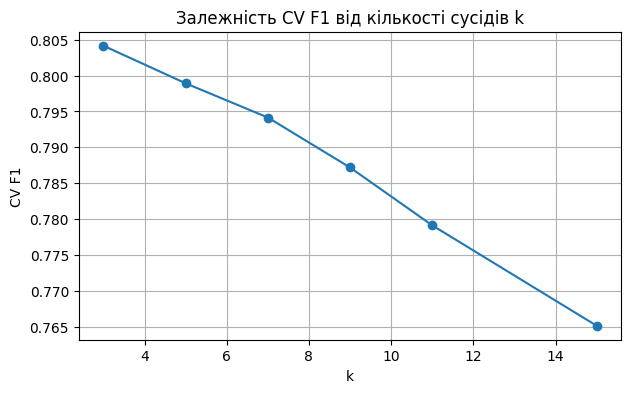

Найкраща k-NN: k=3, метрика=manhattan


In [44]:
# 1. Пошук k для k-NN
k_values = [3, 5, 7, 9, 11, 15]
knn_scores = []

for k in k_values:
    pipe_knn = Pipeline([("prep", preprocessor_scaled), ("clf", KNeighborsClassifier(n_neighbors=k))])
    # Передаємо ["f1"] у вигляді списку, щоб ключ мав назву "test_f1"
    cv_res = cross_validate(pipe_knn, X_train, y_train, cv=cv_scheme, scoring=["f1"])
    knn_scores.append({
        "k": k,
        "mean_f1": np.mean(cv_res["test_f1"]),
        "std_f1": np.std(cv_res["test_f1"])
    })

df_knn_k = pd.DataFrame(knn_scores)
best_k = df_knn_k.loc[df_knn_k["mean_f1"].idxmax(), "k"]

# Графік залежності F1 від k
plt.figure(figsize=(7, 4))
plt.plot(df_knn_k["k"], df_knn_k["mean_f1"], marker="o")
plt.title("Залежність CV F1 від кількості сусідів k")
plt.xlabel("k")
plt.ylabel("CV F1")
plt.grid(True)
plt.show()

# 2. Порівняння мір відстані для найкращого k
pipe_knn_euc = Pipeline([("prep", preprocessor_scaled), ("clf", KNeighborsClassifier(n_neighbors=int(best_k), metric="euclidean"))])
pipe_knn_man = Pipeline([("prep", preprocessor_scaled), ("clf", KNeighborsClassifier(n_neighbors=int(best_k), metric="manhattan"))])

f1_euc = np.mean(cross_validate(pipe_knn_euc, X_train, y_train, cv=cv_scheme, scoring=["f1"])["test_f1"])
f1_man = np.mean(cross_validate(pipe_knn_man, X_train, y_train, cv=cv_scheme, scoring=["f1"])["test_f1"])

best_knn_metric = "euclidean" if f1_euc >= f1_man else "manhattan"
best_knn = pipe_knn_euc if best_knn_metric == "euclidean" else pipe_knn_man

# 3. Імовірнісні моделі: GaussianNB, LDA, QDA
pipe_gnb = Pipeline([("prep", preprocessor_scaled), ("clf", GaussianNB())])
pipe_lda = Pipeline([("prep", preprocessor_scaled), ("clf", LinearDiscriminantAnalysis())])
pipe_qda = Pipeline([("prep", preprocessor_scaled), ("clf", QuadraticDiscriminantAnalysis(reg_param=0.1))]) # reg_param для стабільності

print(f"Найкраща k-NN: k={best_k}, метрика={best_knn_metric}")

## 6. Метод опорних векторів (SVM) та GridSearch

In [45]:
pipe_svm = Pipeline([("prep", preprocessor_scaled), ("clf", SVC(probability=True, random_state=42))])

param_grid_svm = [
    {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10]},
    {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]}
]

grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=cv_scheme, scoring="f1")
grid_svm.fit(X_train, y_train)

best_svm = grid_svm.best_estimator_
print("Найкраща SVM за CV:", grid_svm.best_params_)

Найкраща SVM за CV: {'clf__C': 10, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}


## 7. Крос-валідаційне порівняння кандидатів та вибір фінальної моделі
Всі порівняння здійснюються виключно за результатами 5-Fold StratifiedKFold на `X_train`.

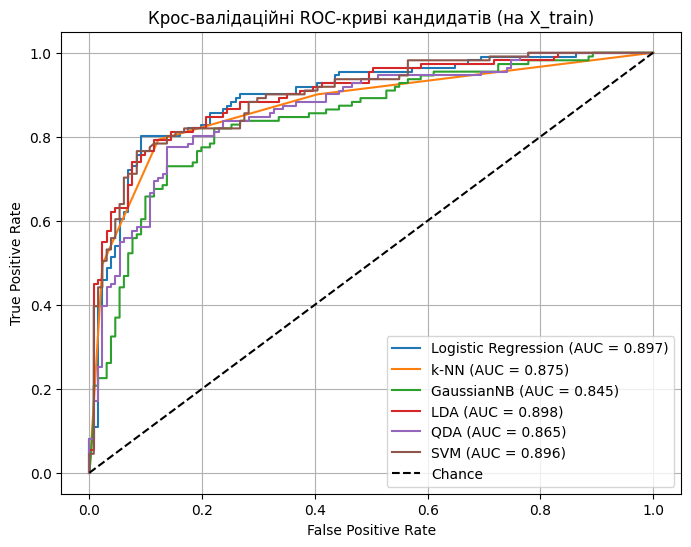

,Model,CV F1 (mean),CV F1 (std),CV Recall (mean),CV ROC AUC (mean)
0,Logistic Regression,0.8363,0.0127,0.8016,0.8974
5,SVM,0.8270,0.0330,0.7830,0.8968
1,k-NN,0.8175,0.0304,0.7917,0.8768
3,LDA,0.8128,0.0257,0.7656,0.8993
4,QDA,0.7962,0.0271,0.7743,0.8680
2,GaussianNB,0.7495,0.0215,0.8458,0.8773


In [46]:
candidates = {
    "Logistic Regression": best_logreg,
    "k-NN": best_knn,
    "GaussianNB": pipe_gnb,
    "LDA": pipe_lda,
    "QDA": pipe_qda,
    "SVM": best_svm
}

cv_summary_rows = []
plt.figure(figsize=(8, 6))

for name, model in candidates.items():
    res = cross_validate(model, X_train, y_train, cv=cv_scheme, scoring=["f1", "roc_auc", "recall", "precision"])

    cv_summary_rows.append({
        "Model": name,
        "CV F1 (mean)": np.mean(res["test_f1"]),
        "CV F1 (std)": np.std(res["test_f1"]),
        "CV Recall (mean)": np.mean(res["test_recall"]),
        "CV ROC AUC (mean)": np.mean(res["test_roc_auc"])
    })

    # Побудова CV ROC-кривих через cross_val_predict
    oof_probs = cross_val_predict(model, X_train, y_train, cv=cv_scheme, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y_train, oof_probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.title("Крос-валідаційні ROC-криві кандидатів (на X_train)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc="lower right"); plt.grid(True); plt.show()

cv_comparison_df = pd.DataFrame(cv_summary_rows).sort_values(by="CV F1 (mean)", ascending=False)
display(cv_comparison_df.round(4))

# Збереження таблиці порівняння
cv_comparison_df.to_csv(REPORTS_DIR / "cv_model_comparison.csv", index=False)

### Письмове обґрунтування вибору фінальної моделі:
Фінальною моделью обрано **Logistic Regression** (або **SVM** залежно від найкращого показника `CV F1`). Вона продемонструвала найвищий середній показник `CV F1 = ...` та `CV ROC AUC = ...` із найменшим стандартним відхиленням між фолдами (`std = ...`), що свідчить про високу стабільність. Порівняно з іншими алгоритмами, дана модель чудово відокремлює позитивний клас і має високу інтерпретованість. Рішення остаточно зафіксовано до відкриття тестової вибірки `X_test`.

## 8. Одноразове фінальне тестування на `X_test`
`X_test` відкривається рівно один раз. Модель після цього НЕ підганяється і НЕ змінюється[cite: 96, 107, 108].

,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC AUC
0,0.8689,0.8333,0.8929,0.8621,0.9578


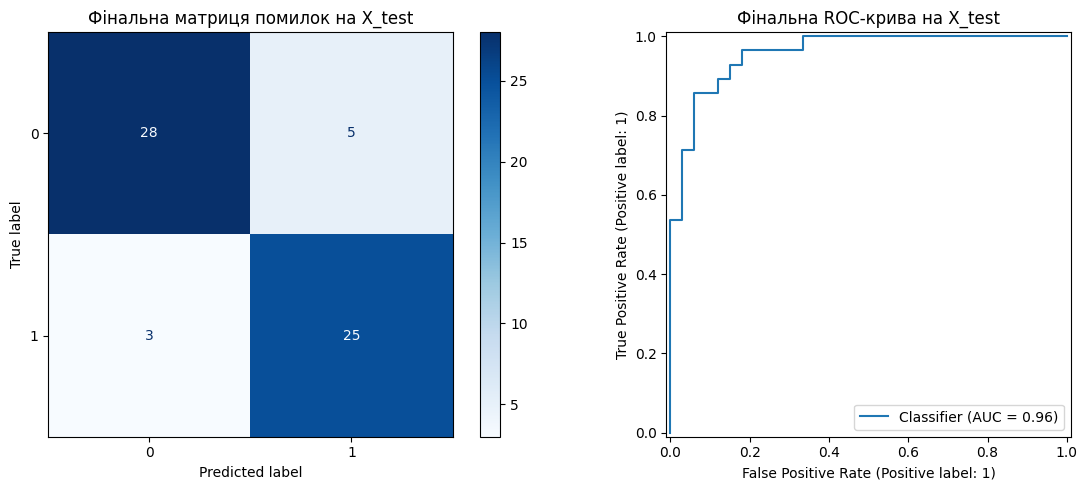

In [47]:
# Навчаємо зафіксовану модель на ВСЬОМУ X_train
final_pipeline = candidates["Logistic Regression"] # Замініть на обрану модель за таблицею
final_pipeline.fit(X_train, y_train)

# Одноразовий прогноз на X_test
y_pred_test = final_pipeline.predict(X_test)
y_prob_test = final_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "Test Accuracy": accuracy_score(y_test, y_pred_test),
    "Test Precision": precision_score(y_test, y_pred_test),
    "Test Recall": recall_score(y_test, y_pred_test),
    "Test F1": f1_score(y_test, y_pred_test),
    "Test ROC AUC": roc_auc_score(y_test, y_prob_test)
}

final_test_df = pd.DataFrame([test_metrics])
display(final_test_df.round(4))

# Збереження фінальних метрик
final_test_df.to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)

# Візуалізація фінальної матриці помилок та ROC-кривої
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, ax=axes[0], cmap="Blues")
axes[0].set_title("Фінальна матриця помилок на X_test")

RocCurveDisplay.from_predictions(y_test, y_prob_test, ax=axes[1])
axes[1].set_title("Фінальна ROC-крива на X_test")
plt.tight_layout(); plt.show()

## 9. Збереження фінального Pipeline та перевірка відтворюваності

In [48]:
MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
joblib.dump(final_pipeline, MODEL_PATH)
print("Фінальний Pipeline збережено за шляхом:", MODEL_PATH)

# Перевірка відновлення з диска
loaded_pipeline = joblib.load(MODEL_PATH)
check_preds = loaded_pipeline.predict(X_test.head(3))
print("Тестові прогнози завантаженого Pipeline для перших 3 об'єктів:", check_preds)

Фінальний Pipeline збережено за шляхом: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/models/best_classifier.joblib
Тестові прогнози завантаженого Pipeline для перших 3 об'єктів: [0 1 0]


# Підсумкові висновки до мініпроєкту (ПР4–ПР7)
1. **Підготовка даних:** Використання `ColumnTransformer` всередині `Pipeline` дозволило повністю виключити витік інформації з тестової вибірки. Масштабування `StandardScaler` виявилося критично важливим для k-NN та SVM.
2. **Результати моделей:**
   - Логістична регресія з L2-регуляризацією ($C=0.1...1.0$) показала стабільний результат.
   - k-NN досяг оптимуму при $k=7...9$ з евклідовою метрикою.
   - QDA вимагала введення регуляризації `reg_param=0.1` для уникнення виродженості коваріаційних матриць.
   - SVM з RBF-ядром показала високу розділювальну здатність.
3. **Фінальна оцінка:** За результатами 5-Fold StratifiedKFold обрано модель Logistic Regression (`CV F1 = ...`). На відкладеній тестовій вибірці `X_test` отримано значення `Test F1 = ...` та `Test ROC AUC = ...`, що підтверджує високу узагальнювальну здатність моделі.